In [15]:
import importlib

import forecaster
import plots 
importlib.reload(plots)
importlib.reload(forecaster)

from forecaster import Forecaster
from plots import visualize_forecast_and_safety_stock


In [6]:
from forecaster import Forecaster
from data_class import SalesDataset
data = SalesDataset('History_SellIn_SellOut.csv', separator=';', nr_horizon=1,target_column = 'Sellout')
data.process_data()
fc = Forecaster(model_name = 'RandomForestRegressor')
fc.gridsearch(data.X_train, data.y_train)
y_pred_test, error = fc.predict(data.X_test, data.y_test)

Dataset shape: (6804, 9)
Processing Dataset 1 for Sellout
Train period: 2018-09-22 00:00:00 - 2019-09-22 00:00:00 (1y)
Test period: 2019-09-22 00:00:00 - 2019-12-22 00:00:00 (3m)
Fitting 5 folds for each of 6 candidates, totalling 30 fits


KeyboardInterrupt: 

Dataset shape: (6804, 9)
Processing Dataset 1 for Sellout
Train period: 2018-06-22 00:00:00 - 2019-06-22 00:00:00 (1y)
Test period: 2019-06-22 00:00:00 - 2019-12-22 00:00:00 (6m)
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'regressor__criterion': 'squared_error', 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 3, 'regressor__n_estimators': 100}
11.50800953697717


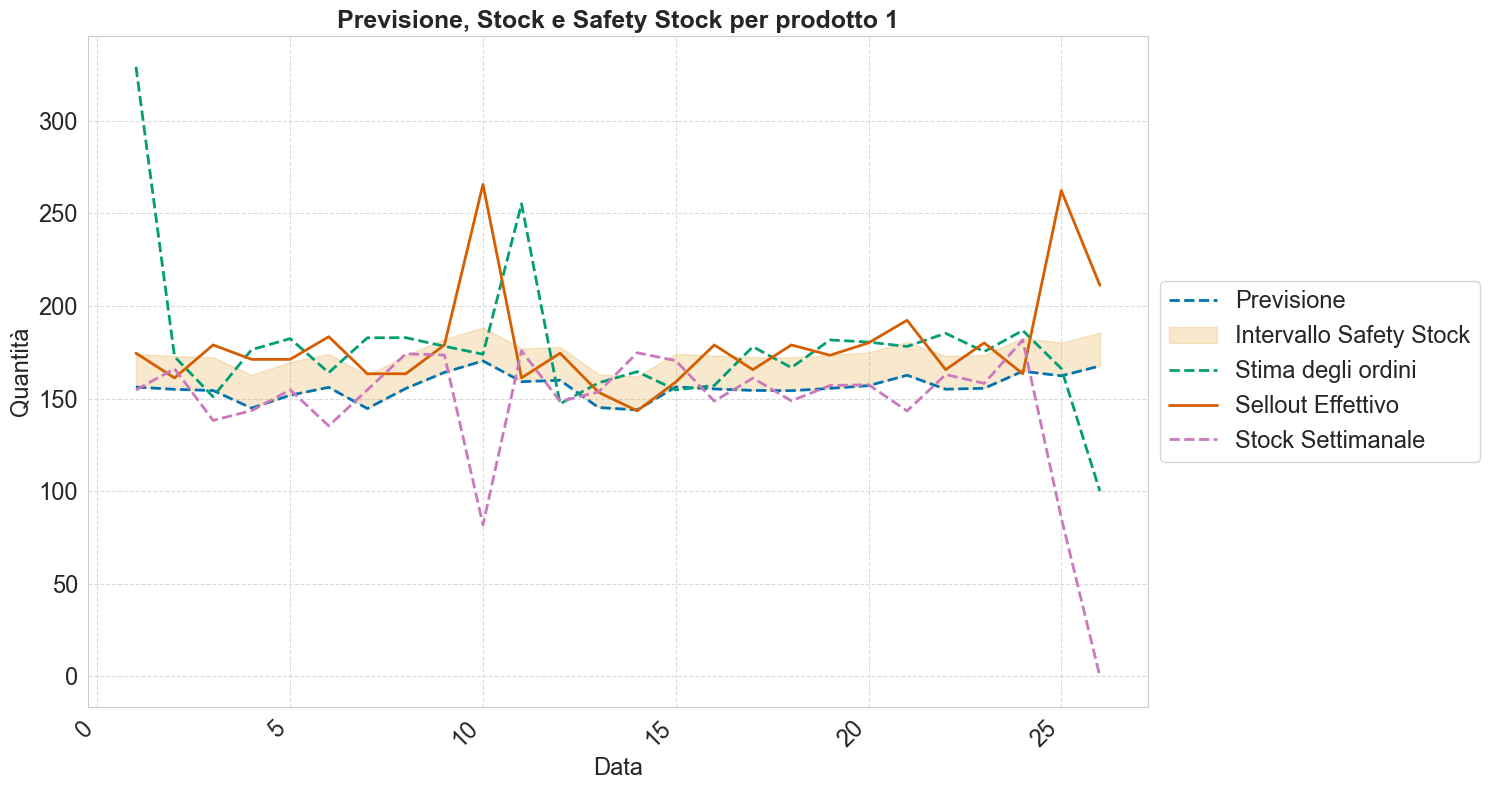

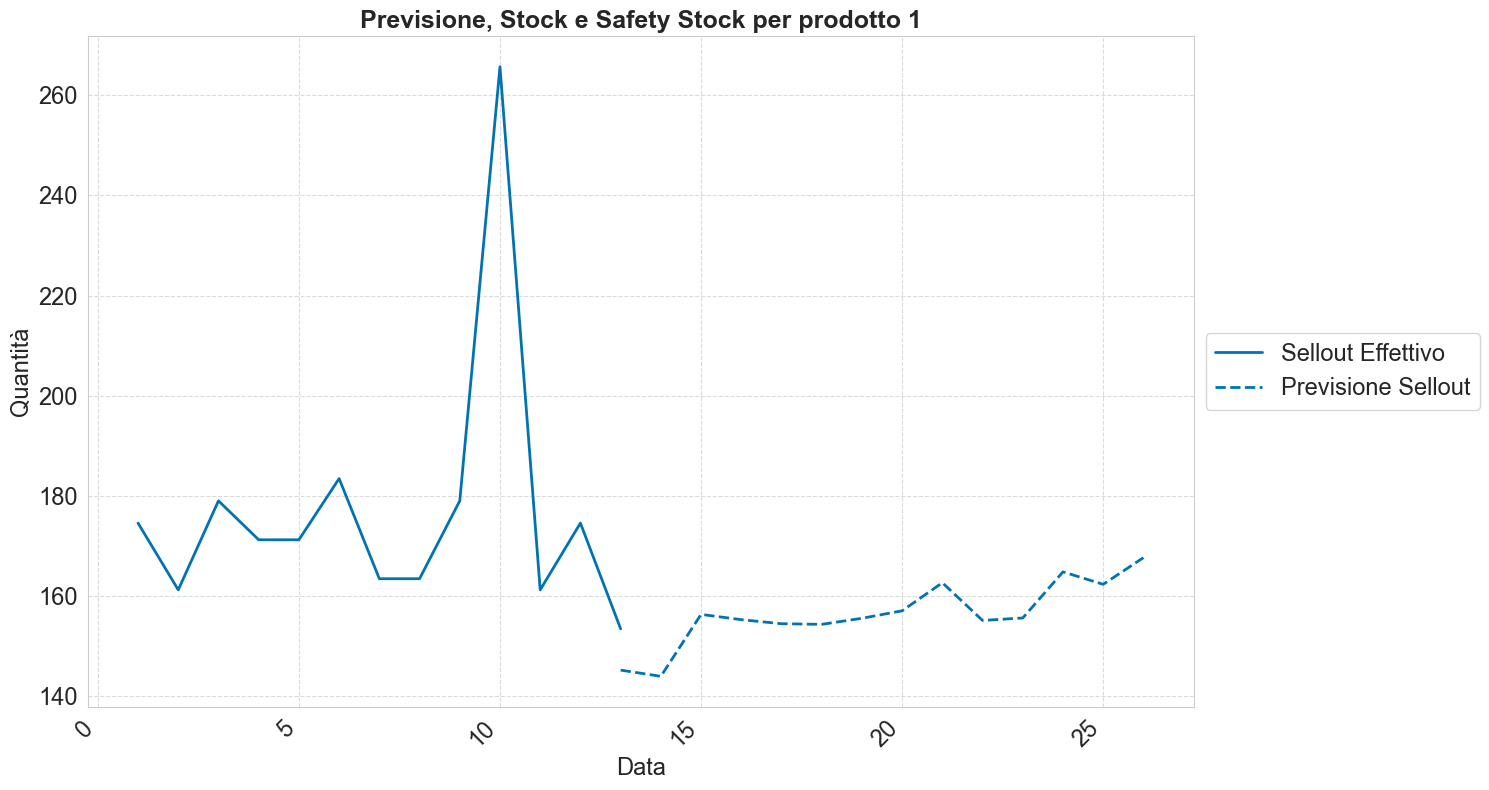

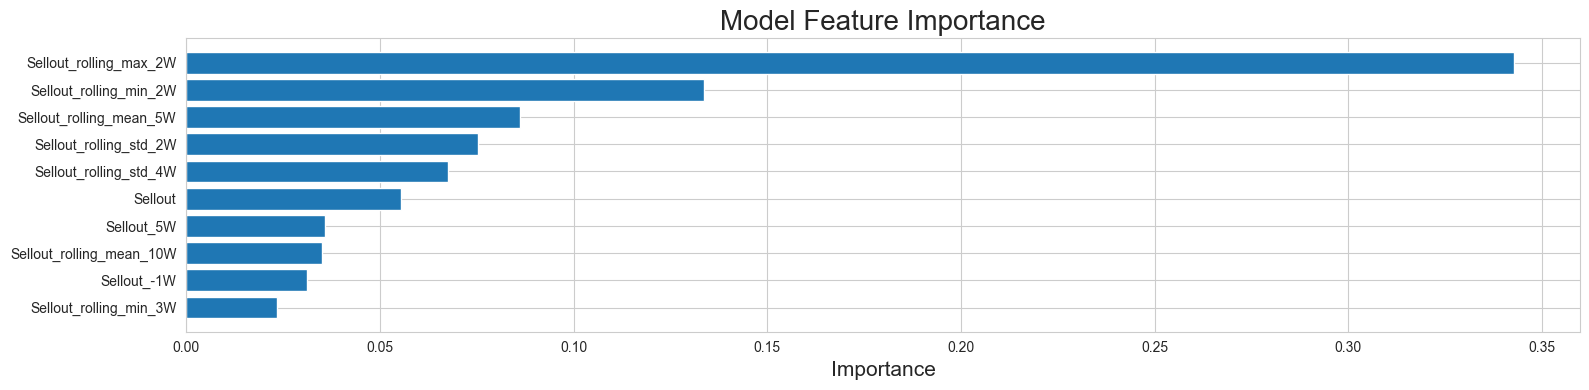

ValueError: too many values to unpack (expected 5)

In [ ]:
from forecaster import Forecaster
from data_class import SalesDataset

p = 'Product_01'
p_data = SalesDataset('History_SellIn_SellOut.csv', separator=';', nr_horizon=1,target_column = 'Sellout')
p_data.process_data(product=p, 
                    train_params = {'train_len': '1y', 
                                    'test_len' : '6m',
                                    'boundary' : None
})
p_fc = Forecaster(model_name = 'RandomForestRegressor')
p_fc.gridsearch(p_data.X_train, p_data.y_train)
p_y_pred, p_error = p_fc.predict(p_data.X_test, p_data.y_test)
p_ytrain_pred, _ = p_fc.predict(p_data.X_train, p_data.y_train)
print(p_error)
# sell in for plotting reasons
sell_in = p_data.X_test['dispatches_SellIn']
stock, forecast_sell_in, lost_sales, safety_stock, service_level,stock_cover = p_fc.stock_analysis(p_data.y_test, 
                                                                p_y_pred,
                                                                p_data.y_train,
                                                                p_ytrain_pred,sell_in)
p_fc.scenario_analysis(p_data.y_test, p_y_pred,p_data.y_train,p_ytrain_pred,sell_in,MAPE = p_error)


In [9]:

p_data.X_train

,Sellout_rolling_std_5W,dispatches_SellIn,Sellout_rolling_min_5W,PERIOD_TAG_cos,Sellout_3W,Sellout_2W,type_promo_1,type_promo_1_1W,Sellout_rolling_mean_5W,Sellout_rolling_max_2W,...,Sellout_-1W,numeric_distribution_selling_promotion,Sellout_rolling_std_3W,Sellout_5W,Sellout_rolling_max_3W,Sellout_rolling_min_3W,type_promo_2_current,Sellout_4W,type_promo_1_current,Sellout_rolling_min_4W
4083,36.418153,173,113.390783,0.992981,130.065898,118.949154,0.0,0.0,136.958279,121.172503,...,131.177572,0.0,4.008199,117.837480,121.172503,113.390783,0.0,201.213055,0.0,113.390783
4106,7.564288,58,113.390783,0.582979,118.949154,121.172503,0.0,0.0,122.951182,131.177572,...,188.984638,0.0,8.916525,201.213055,131.177572,113.390783,0.0,130.065898,0.0,113.390783
4162,31.001566,117,113.390783,-0.205979,121.172503,113.390783,0.0,0.0,134.734930,188.984638,...,131.177572,4.9,39.523111,130.065898,188.984638,113.390783,0.0,118.949154,0.0,113.390783
4193,29.907965,115,113.390783,-0.861044,113.390783,131.177572,0.0,0.0,137.180613,188.984638,...,123.395852,0.0,33.374925,118.949154,188.984638,131.177572,0.0,121.172503,0.0,113.390783
4222,29.625652,115,113.390783,-0.956401,131.177572,188.984638,0.0,0.0,137.625283,131.177572,...,107.832411,0.0,35.833180,121.172503,188.984638,123.395852,0.0,113.390783,0.0,123.395852
4298,30.841701,5,107.832411,-0.430065,188.984638,131.177572,0.0,0.0,136.513609,123.395852,...,131.177572,0.0,11.886774,113.390783,131.177572,107.832411,0.0,131.177572,0.0,107.832411
4324,30.841701,58,107.832411,0.375828,131.177572,123.395852,0.0,0.0,136.513609,131.177572,...,143.405990,0.0,11.886774,131.177572,131.177572,107.832411,0.0,188.984638,0.0,107.832411
4379,13.073404,289,107.832411,0.937420,123.395852,107.832411,0.0,0.0,127.397879,143.405990,...,113.390783,0.0,18.073970,188.984638,143.405990,107.832411,0.0,131.177572,0.0,107.832411
4388,14.162399,288,107.832411,0.889657,107.832411,131.177572,0.0,0.0,123.840521,143.405990,...,121.172503,0.0,15.093137,131.177572,143.405990,113.390783,0.0,123.395852,0.0,107.832411
4442,14.214659,2,107.832411,0.263587,131.177572,143.405990,0.0,0.0,123.395852,121.172503,...,137.847618,0.0,15.576669,123.395852,143.405990,113.390783,0.0,107.832411,0.0,113.390783


In [ ]:
visualize_forecast_and_safety_stock('Product_01',)


In [ ]:
import pandas as pd
df = pd.read_csv(r"C:\Users\fraca\Desktop\sales\Sell_Out_Sell_In_Forecasting-main\dataset_definitivo_strutturato.csv")



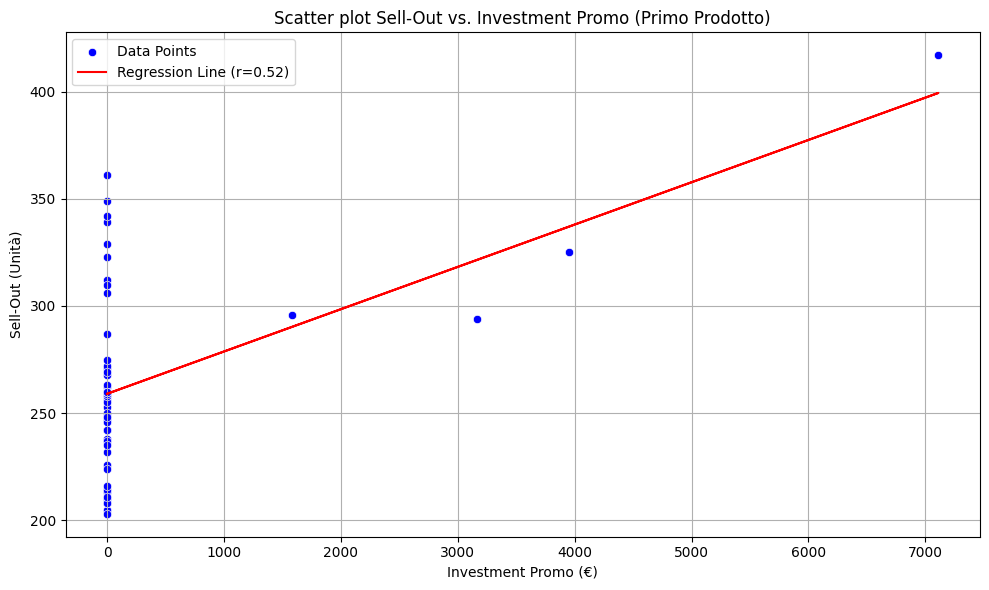

np.float64(0.5166125019115496)

In [12]:
# Import librerie necessarie
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Caricamento del dataset

# Seleziona solo il primo prodotto (due righe: sell-out e investimento)
sell_out = df.iloc[0, 5:].astype(float).values
investment_promo = df.iloc[1, 5:].astype(float).values

# Calcolo correlazione
correlation = pd.Series(sell_out).corr(pd.Series(investment_promo))

# Fit linea di regressione
slope, intercept, r_value, p_value, std_err = linregress(investment_promo, sell_out)

# Scatter plot
plt.figure(figsize=(10,6))
sns.scatterplot(x=investment_promo, y=sell_out, color='blue', label='Data Points')

# Aggiungi linea di regressione
plt.plot(investment_promo, intercept + slope * investment_promo, 'r', label=f'Regression Line (r={correlation:.2f})')

# Etichette e titolo
plt.xlabel('Investment Promo (€)')
plt.ylabel('Sell-Out (Unità)')
plt.title('Scatter plot Sell-Out vs. Investment Promo (Primo Prodotto)')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

# Restituisco correlazione per chiarezza
correlation
